# 10. Mistake analysis

In [1]:
import pandas as pd
g = pd.read_json("../outputs/generations.jsonl", lines=True)
g = g.drop_duplicates(subset=["model", "prompt", "temperature", "top_k"], keep="last")
g["model"] = g["model"].str.replace("outputs/", "").str.replace("/model", "")

# Candidates: most repetitive first, then read the high-temperature ones
g.sort_values("distinct_2")[["model", "prompt", "temperature", "top_k", "distinct_2", "text"]].head(10)

# Export for manual labelling
g["failure"] = ""        # fill in: repetition / incoherent / factual / off_domain / ... / ok
g.to_csv("../outputs/generations_to_label.csv", index=False)

In [2]:
import pandas as pd

lab = pd.read_csv("../outputs/generations_labeled.csv")
lab["failure"] = lab["failure"].str.split(",")
lab = lab.explode("failure")
lab["failure"] = lab["failure"].str.strip()

# Failures per model
pd.crosstab(lab["model"], lab["failure"])

# Failures per temperature: shows which settings cause which errors
pd.crosstab([lab["model"], lab["temperature"]], lab["failure"])

failure                 blank_lines  domain_leak  gibberish  incoherent  none  \
model      temperature                                                          
distilgpt2 0.4                    0            0          0           0     0   
           0.7                    1            0          0           0     4   
           1.0                    1            0          3           1    10   
           1.3                    0            0          4           9     3   
           1.6                    1            0          4           9     1   
full       0.4                    0            0          0           0     0   
           0.7                    0            0          0           0     6   
           1.0                    0            2          1           0    13   
           1.3                    0            2          4           6     4   
           1.6                    0            1          4           9     1   

failure                 repetition  
model      temperature              
distilgpt2 0.4                  16  
           0.7                  11  
           1.0                   1  
           1.3                   0  
           1.6                   1  
full       0.4                  16  
           0.7                  10  
           1.0                   0  
           1.3                   0  
           1.6                   1

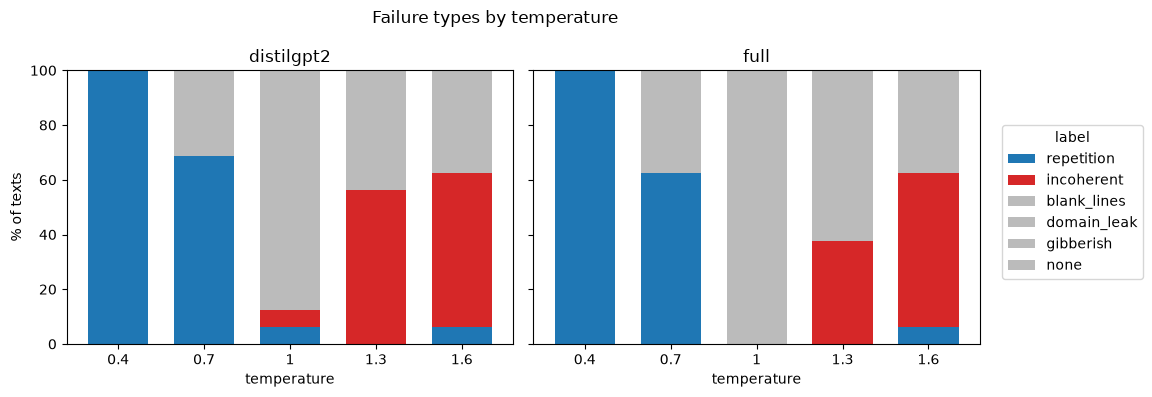

In [5]:
import matplotlib.pyplot as plt

# --- Load labelled data -------------------------------------------------------
lab = pd.read_csv("../outputs/generations_labeled.csv")
lab["model_short"] = (lab["model"].str.replace("../", "", regex=False)
                                  .str.replace("outputs/", "", regex=False)
                                  .str.replace("/model", "", regex=False))
lab["temperature"] = lab["temperature"].round(2)
lab["failure"] = lab["failure"].fillna("").str.strip()
lab = lab[lab["failure"] != ""].copy()          # skip rows you haven't labelled yet
lab["text_id"] = range(len(lab))

# One row per (text, tag), since a text can have several tags ("factual, contradiction")
long = lab.assign(failure=lab["failure"].str.split(",")).explode("failure")
long["failure"] = long["failure"].str.strip()

# Fixed order + colours so every subplot uses the same legend
ORDER = ["ok", "repetition", "incoherent", "factual", "off_domain",
         "domain_overreach", "contradiction", "copied"]
COLORS = {"ok": "#9e9e9e", "repetition": "#1f77b4", "incoherent": "#d62728",
          "factual": "#ff7f0e", "off_domain": "#9467bd", "domain_overreach": "#8c564b",
          "contradiction": "#e377c2", "copied": "#17becf"}
tags = [t for t in ORDER if t in long["failure"].unique()] + \
       sorted(set(long["failure"]) - set(ORDER))     # any extra tags you invented
models = lab["model_short"].unique()

# --- Figure 1: share of texts with each tag, per temperature -----------------
n_texts = lab.groupby(["model_short", "temperature"]).size()
counts = (long.groupby(["model_short", "temperature", "failure"])["text_id"]
              .nunique().unstack(fill_value=0))
share = counts.div(n_texts, axis=0) * 100

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False, sharey=True)
for ax, m in zip(axes[0], models):
    s = share.loc[m].reindex(columns=tags, fill_value=0)
    s.plot.bar(stacked=True, ax=ax, color=[COLORS.get(t, "#bbbbbb") for t in tags],
               width=0.7, legend=False)
    ax.set_title(m); ax.set_xlabel("temperature"); ax.set_ylabel("% of texts")
    ax.set_xticklabels([f"{t:g}" for t in s.index], rotation=0)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, title="label", loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle("Failure types by temperature")
plt.tight_layout(); plt.show()